# Activity 2: Social Network Ads Purchase Prediction using Logistic Regression

## Problem Statement
To predict whether a customer will purchase a product based on age and estimated salary and help the marketing team identify potential customers.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.dummy import DummyClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, roc_curve

In [2]:
import sklearn
import matplotlib

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 2.4.0
Pandas: 2.3.3
Matplotlib: 3.10.8
Seaborn: 0.13.2
Scikit-learn: 1.8.0


In [3]:
df = pd.read_csv("Social_Network_Ads.csv")

In [4]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [5]:
df.shape

(400, 5)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [7]:
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


In [8]:
df.isnull().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
print("Target Labels:", df["Purchased"].unique())

Target Labels: [0 1]


In [11]:
print("Class Distribution:")
print(df["Purchased"].value_counts())

Class Distribution:
Purchased
0    257
1    143
Name: count, dtype: int64


In [12]:
print("Class Percentage:")
print((df["Purchased"].value_counts(normalize=True)*100).round(2))

Class Percentage:
Purchased
0    64.25
1    35.75
Name: proportion, dtype: float64


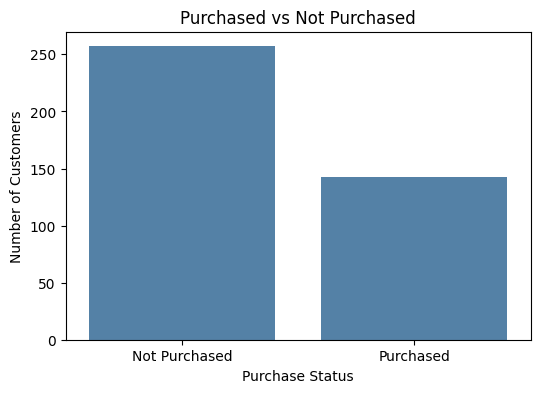

In [13]:
# Purchased customers
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Purchased", color="steelblue")

plt.title("Purchased vs Not Purchased")
plt.xlabel("Purchase Status")
plt.ylabel("Number of Customers")
plt.xticks([0,1], ["Not Purchased", "Purchased"])
plt.show()

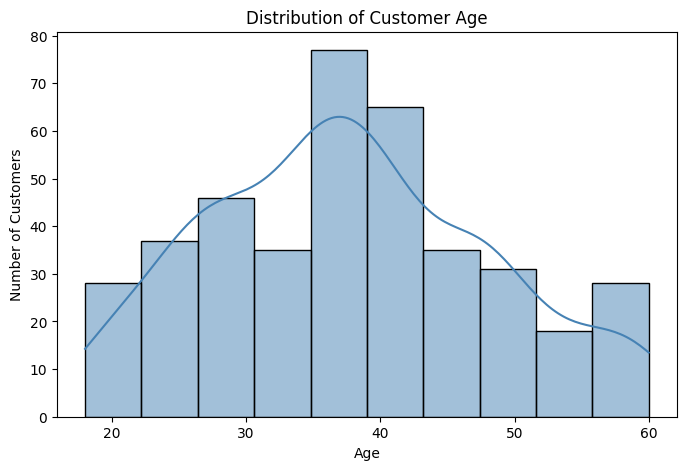

In [14]:
# Age distribution
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Age", kde=True, color="steelblue")

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

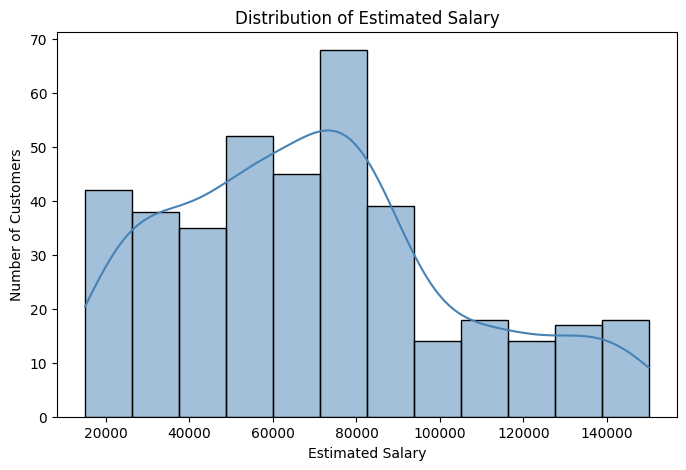

In [15]:
# Estimated salary distribution
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="EstimatedSalary", kde=True, color="steelblue")

plt.title("Distribution of Estimated Salary")
plt.xlabel("Estimated Salary")
plt.ylabel("Number of Customers")
plt.show()

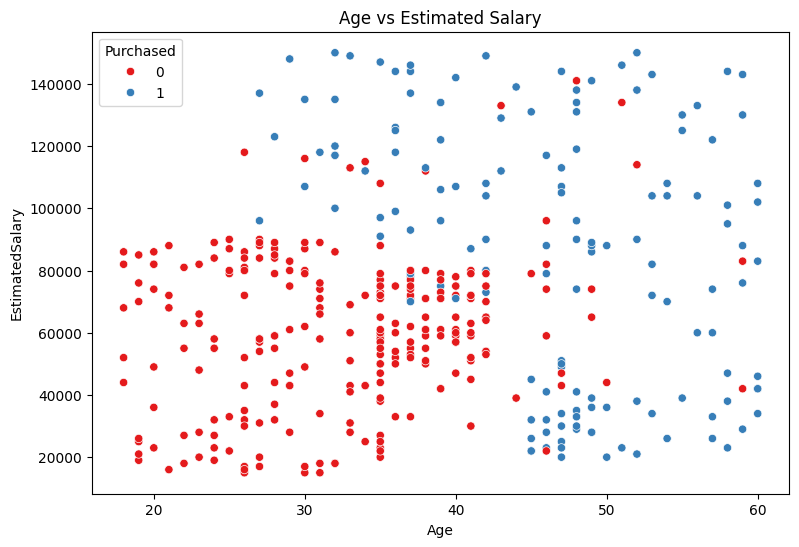

In [16]:
# Age versus salary
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x="Age",
    y="EstimatedSalary",
    hue="Purchased",
    palette="Set1"
)

plt.title("Age vs Estimated Salary")

plt.show()

In [17]:
X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

In [18]:
print("Independent Variables:")
display(X.head())

Independent Variables:


,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000


In [19]:
print("Dependent Variable:")
display(y.head())

Dependent Variable:


0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [21]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (320, 2)
Testing data: (80, 2)


In [22]:
print("Training Class Distribution:")
print(y_train.value_counts())

Training Class Distribution:
Purchased
0    206
1    114
Name: count, dtype: int64


In [23]:
print("Testing Class Distribution:")
print(y_test.value_counts())

Testing Class Distribution:
Purchased
0    51
1    29
Name: count, dtype: int64


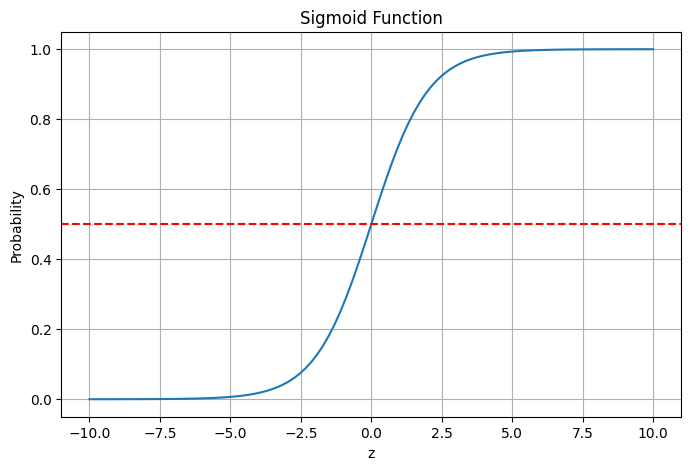

In [24]:
z = np.linspace(-10, 10, 100)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8,5))
plt.plot(z, sigmoid)
plt.axhline(y=0.5, color="red", linestyle="--")
plt.title("Sigmoid Function")
plt.xlabel("z")
plt.ylabel("Probability")
plt.grid()
plt.show()

In [25]:
scaler = StandardScaler()

In [26]:
# Fit and transform training data And transform testing data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [27]:
model = LogisticRegression()

In [28]:
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [29]:
print("Model Settings:")
print(model.get_params())

Model Settings:
{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 100, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [30]:
print("Intercept:", round(model.intercept_[0], 4))

Intercept: -1.1212


In [31]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

print(coefficients.round(4))

           Feature  Coefficient
0              Age       2.1807
1  EstimatedSalary       1.2434


In [32]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [33]:
print("Actual:",y_test.values[:5])
print("Predicted:", y_pred[:5])

Actual: [1 0 0 0 0]
Predicted: [1 0 0 1 0]


In [34]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Predicted Probability": y_prob
})

print(results.head(10).round(4))

   Actual  Predicted  Predicted Probability
0       1          1                 0.9438
1       0          0                 0.0045
2       0          0                 0.0330
3       0          1                 0.6284
4       0          0                 0.0143
5       1          1                 0.9086
6       0          0                 0.4040
7       1          1                 0.9907
8       0          1                 0.9778
9       0          0                 0.0624


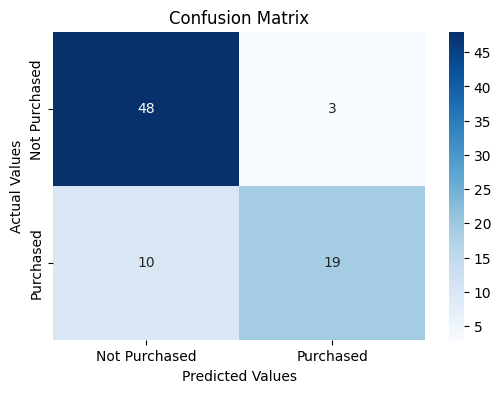

In [35]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Purchased", "Purchased"],
            yticklabels=["Not Purchased", "Purchased"])

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix")
plt.show()

In [36]:
tn, fp, fn, tp = cm.ravel()

print("True Positive:", tp)
print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)

True Positive: 19
True Negative: 48
False Positive: 3
False Negative: 10


In [37]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

metrics = pd.Series({
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "Specificity": specificity,
    "F1-score": f1,
    "ROC-AUC": roc_auc
})

print(metrics.round(4))

Accuracy       0.8375
Precision      0.8636
Recall         0.6552
Specificity    0.9412
F1-score       0.7451
ROC-AUC        0.9053
dtype: float64


In [38]:
evaluation_results = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision", "Recall",
        "Specificity", "F1-score", "ROC-AUC"
    ],
    "Formula": [
        "(TP + TN) / (TP + TN + FP + FN)",
        "TP / (TP + FP)",
        "TP / (TP + FN)",
        "TN / (TN + FP)",
        "2 * Precision * Recall / (Precision + Recall)",
        "Area under ROC curve"
    ],
    "Result": [
        accuracy, precision, recall,
        specificity, f1, roc_auc
    ]
})

display(evaluation_results.round(4))

,Metric,Formula,Result
0,Accuracy,(TP + TN) / (TP + TN + FP + FN),0.8375
1,Precision,TP / (TP + FP),0.8636
2,Recall,TP / (TP + FN),0.6552
3,Specificity,TN / (TN + FP),0.9412
4,F1-score,2 * Precision * Recall / (Precision + Recall),0.7451
5,ROC-AUC,Area under ROC curve,0.9053


In [39]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Logistic Regression Accuracy:", round(accuracy, 4))

Baseline Accuracy: 0.6375
Logistic Regression Accuracy: 0.8375


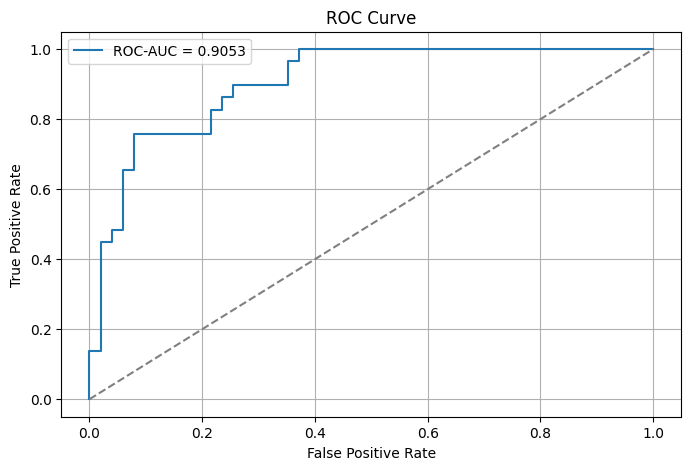

In [40]:
# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8,5))

plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0,1], [0,1], linestyle="--", color="gray")

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

In [41]:
# Threshold comparison
threshold_results = []

for threshold in [0.3, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)

    threshold_results.append([
        threshold,
        pred.sum(),
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred)
    ])

threshold_df = pd.DataFrame(threshold_results, columns=[
    "Threshold", "Predicted Positive", "Accuracy",
    "Precision", "Recall", "F1-score"
])

print(threshold_df.round(4))

   Threshold  Predicted Positive  Accuracy  Precision  Recall  F1-score
0        0.3                  38    0.7875     0.6579  0.8621    0.7463
1        0.5                  22    0.8375     0.8636  0.6552    0.7451
2        0.7                  14    0.7875     0.9286  0.4483    0.6047


In [42]:
# Training vs testing performance
y_train_pred = model.predict(X_train_scaled)

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Training": [
        accuracy_score(y_train, y_train_pred),
        precision_score(y_train, y_train_pred),
        recall_score(y_train, y_train_pred),
        f1_score(y_train, y_train_pred)
    ],
    "Testing": [accuracy, precision, recall, f1]
})

print(comparison.round(4))

      Metric  Training  Testing
0   Accuracy    0.8469   0.8375
1  Precision    0.8351   0.8636
2     Recall    0.7105   0.6552
3   F1-score    0.7678   0.7451


In [43]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.94      0.88        51
           1       0.86      0.66      0.75        29

    accuracy                           0.84        80
   macro avg       0.85      0.80      0.81        80
weighted avg       0.84      0.84      0.83        80



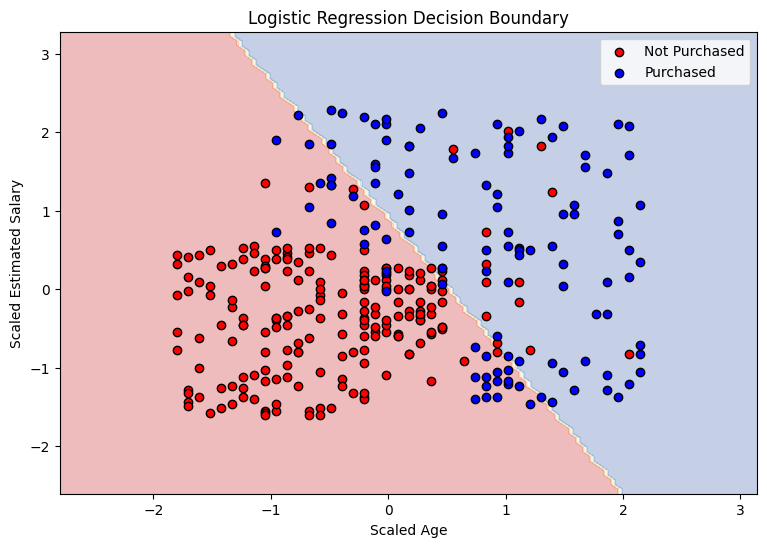

In [44]:
fig, ax = plt.subplots(figsize=(9,6))

DecisionBoundaryDisplay.from_estimator(
    model, X_train_scaled,
    response_method="predict",
    cmap="RdYlBu", alpha=0.3, ax=ax
)

ax.scatter(
    X_train_scaled[y_train == 0, 0],
    X_train_scaled[y_train == 0, 1],
    color="red", edgecolors="black",
    label="Not Purchased"
)

ax.scatter(
    X_train_scaled[y_train == 1, 0],
    X_train_scaled[y_train == 1, 1],
    color="blue", edgecolors="black",
    label="Purchased"
)

plt.xlabel("Scaled Age")
plt.ylabel("Scaled Estimated Salary")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.show()

In [45]:
# New customer details
new_customer = pd.DataFrame({
    "Age": [35],
    "EstimatedSalary": [60000]
})

# Apply the same scaler
new_customer_scaled = scaler.transform(new_customer)

# Make prediction
prediction = model.predict(new_customer_scaled)
probability = model.predict_proba(new_customer_scaled)

print("Predicted Class:", prediction[0])
print("Purchase Probability:", round(probability[0][1]*100, 2), "%")

if prediction[0] == 1:
    print("Customer is likely to purchase the product.")
else:
    print("Customer is unlikely to purchase the product.")

Predicted Class: 0
Purchase Probability: 12.47 %
Customer is unlikely to purchase the product.


## Results and Conclusion

The model achieved 83.75% testing accuracy compared
with the majority-class baseline of 63.75%.

The confusion matrix contains 19 true positives,
48 true negatives, 3 false positives and
10 false negatives.

Precision of 86.36% indicates reliable positive
predictions, while recall of 65.52% indicates that
some potential customers were missed.

Specificity is 94.12%, F1-score is 74.51%, and
ROC-AUC is 0.9053, indicating good discrimination
between purchasing and non-purchasing customers.

Accuracy alone can be misleading because the
dataset is moderately imbalanced.

Training accuracy (84.69%) and testing accuracy
(83.75%) are close, indicating no obvious severe
overfitting.

The decision boundary separates the two classes,
although some customers overlap.

## Limitations

The model considers only two features. Other factors
such as product price and customer interests may
influence purchasing decisions.

Incorrect predictions may lead to wasted advertising
expenses or missed customers.

Predictions are probability-based estimates and
not guaranteed outcomes.